In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Environment ready!")

TensorFlow version: 2.21.0
Environment ready!


In [2]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


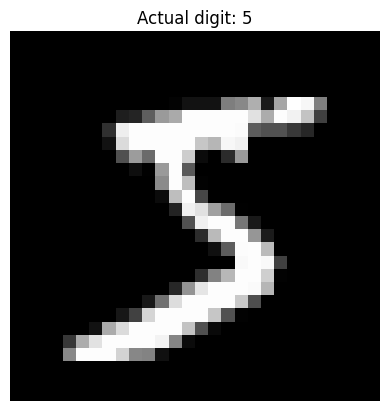

In [3]:
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Actual digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [4]:
# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Image shape:", x_train.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Image shape: (60000, 28, 28)


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8973 - loss: 0.3600 - val_accuracy: 0.9605 - val_loss: 0.1485
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9564 - loss: 0.1481 - val_accuracy: 0.9717 - val_loss: 0.1034
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9699 - loss: 0.1026 - val_accuracy: 0.9710 - val_loss: 0.0966
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9768 - loss: 0.0779 - val_accuracy: 0.9745 - val_loss: 0.0814
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9811 - loss: 0.0620 - val_accuracy: 0.9773 - val_loss: 0.0773
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9844 - loss: 0.0512 - val_accuracy: 0.9778 - val_loss: 0.0808
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9879 - loss: 0.0404 - val_accuracy: 0.9792 - val_loss: 0.0742
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9900 - loss: 0.0334 - val_accuracy: 0.

In [8]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

Test loss: 0.0838
Test accuracy: 97.67%


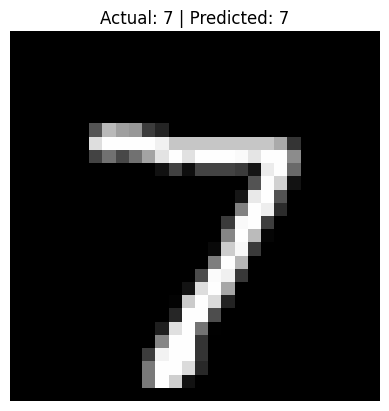

Predicted probabilities: [1.2204751e-08 2.5426760e-07 6.2115606e-07 5.5878812e-05 7.3158406e-12
 2.4108424e-09 1.8370654e-13 9.9992061e-01 9.1184425e-08 2.2522652e-05]


In [9]:
index = 0

probabilities = model.predict(
    x_test[index:index + 1],
    verbose=0
)

predicted_digit = np.argmax(probabilities[0])

plt.imshow(x_test[index], cmap="gray")
plt.title(
    f"Actual: {y_test[index]} | Predicted: {predicted_digit}"
)
plt.axis("off")
plt.show()

print("Predicted probabilities:", probabilities[0])

In [10]:
# Test 10 unseen images
predictions = model.predict(x_test[:10], verbose=0)
predicted_digits = np.argmax(predictions, axis=1)

for i in range(10):
    print(
        f"Actual: {y_test[i]} | "
        f"Predicted: {predicted_digits[i]} | "
        f"Correct: {y_test[i] == predicted_digits[i]}"
    )

Actual: 7 | Predicted: 7 | Correct: True
Actual: 2 | Predicted: 2 | Correct: True
Actual: 1 | Predicted: 1 | Correct: True
Actual: 0 | Predicted: 0 | Correct: True
Actual: 4 | Predicted: 4 | Correct: True
Actual: 1 | Predicted: 1 | Correct: True
Actual: 4 | Predicted: 4 | Correct: True
Actual: 9 | Predicted: 9 | Correct: True
Actual: 5 | Predicted: 5 | Correct: True
Actual: 9 | Predicted: 9 | Correct: True


In [11]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = np.argmax(
    model.predict(x_test, verbose=0),
    axis=1
)

print(classification_report(y_test, y_pred))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.97      1032
           3       0.96      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.97      0.97       892
           6       0.97      0.98      0.98       958
           7       0.96      0.99      0.97      1028
           8       0.97      0.97      0.97       974
           9       0.98      0.95      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

Confusion matrix:
[[ 967    0    2    3    1    1    3    1    2    0]
 [   0 1125    3    1    0    0    2    1    3    0]
 [   3    3  999    3    5    0    3    9    6    1]
 [   0    0    4  994    0    3    0    3    3    3]
 [   0    0